In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.linalg import solve
from scipy.optimize import nnls
from statistics import mean, variance, stdev
from timeit import timeit
from pathlib import Path

In [2]:
from src.microgrid import MicroGrid, HybridMicroGrid, solve_with_nnls

grid = MicroGrid()

print("Determinant:", grid.determinant)
print("Condition number:", grid.condition_number)
print("Test solution:", grid.solve_day(30, 20))

Determinant: -4.999999999999999
Condition number: 5.82842712474619
Test solution: {'solar_kwh': np.float64(2.0), 'battery_kwh': np.float64(12.0), 'feasible': True}


In [3]:
A = np.array([
    [3, 2],
    [4, 1]
], dtype=float)

determinant = np.linalg.det(A)
condition_number = np.linalg.cond(A)

print("Coefficient matrix:")
print(A)

print(f"\nDeterminant: {determinant:.2f}")
print(f"Condition number: {condition_number:.4f}")

Coefficient matrix:
[[3. 2.]
 [4. 1.]]

Determinant: -5.00
Condition number: 5.8284


In [4]:
grid = MicroGrid()

print("Determinant:", grid.determinant)
print("Condition number:", grid.condition_number)

result = grid.solve_day(30, 20)
print(result)

Determinant: -4.999999999999999
Condition number: 5.82842712474619
{'solar_kwh': np.float64(2.0), 'battery_kwh': np.float64(12.0), 'feasible': True}


In [5]:

def get_nonnegative_demand(prompt):
    """Keep asking until the user enters a valid non-negative number."""
    while True:
        user_input = input(prompt).strip()

        if not user_input:
            print("Input cannot be empty. Please try again.")
            continue

        try:
            value = float(user_input)
        except ValueError:
            print("Please enter a numeric value.")
            continue

        if not np.isfinite(value):
            print("Please enter a finite number.")
            continue

        if value < 0:
            print("Demand cannot be negative. Please try again.")
            continue

        return value


def run_interactive_day(grid):
    """Read daily demands and solve the micro-grid system."""
    d1 = get_nonnegative_demand("Enter daytime demand D1 (kWh): ")
    d2 = get_nonnegative_demand("Enter critical-equipment demand D2 (kWh): ")

    result = grid.solve_day(d1, d2)

    print("\nDaily dispatch result")
    print(f"Solar usage: {result['solar_kwh']:.2f} kWh")
    print(f"Battery usage: {result['battery_kwh']:.2f} kWh")
    print(f"Physically feasible: {result['feasible']}")

    if not result["feasible"]:
        print("Warning: the mathematical solution includes negative energy usage.")

    return result


In [6]:
interactive_result = run_interactive_day(grid)


Daily dispatch result
Solar usage: 2.00 kWh
Battery usage: 12.00 kWh
Physically feasible: True


In [7]:

# import numpy as np
# import pandas as pd
# from pathlib import Path

# # Reproducible random generator
# rng = np.random.default_rng(42)

# # Generate 30 days
# days = np.arange(1, 31)

# # Weekly demand pattern: Monday to Sunday
# weekly_pattern = np.array([
#     1.00, 1.05, 1.08, 1.04, 1.02, 0.90, 0.85
# ])

# # Repeat the pattern across 30 days
# weekly_factor = weekly_pattern[(days - 1) % 7]

# # Generate daily demands with random noise
# D1 = 30 * weekly_factor + rng.normal(0, 1.5, size=30)
# D2 = 20 * weekly_factor + rng.normal(0, 1.0, size=30)

# # Demand cannot be negative
# D1 = np.maximum(D1, 0)
# D2 = np.maximum(D2, 0)

# # Create the dataset
# demand_df = pd.DataFrame({
#     "day": days,
#     "D1_kwh": D1.round(2),
#     "D2_kwh": D2.round(2)
# })

# # Save in the Project 2 folder within the shared repository
# project_dir = Path("project2_solar_microgrid")
# project_dir.mkdir(parents=True, exist_ok=True)

# csv_path = project_dir / "demands_30_days.csv"
# demand_df.to_csv(csv_path, index=False)

# # Display and verify the data
# display(demand_df)

# print(f"\nNumber of days: {len(demand_df)}")
# print(f"Missing values:\n{demand_df.isna().sum()}")
# print(f"\nCSV saved at:\n{csv_path.resolve()}")


In [8]:
demand_df = pd.read_csv("demands_30_days.csv")

In [9]:
def solve_with_loop(grid, demand_df):
    """Solve daily micro-grid demands one day at a time."""
    results = []

    for _, row in demand_df.iterrows():
        demands = np.array([
            row["D1_kwh"],
            row["D2_kwh"]
        ])

        usage = solve(grid.matrix, demands)

        results.append({
            "day": row["day"],
            "D1_kwh": row["D1_kwh"],
            "D2_kwh": row["D2_kwh"],
            "solar_kwh": usage[0],
            "battery_kwh": usage[1],
            "feasible": bool(np.all(usage >= 0))
        })

    return pd.DataFrame(results)


loop_results = solve_with_loop(grid, demand_df)

display(loop_results.head(10).round(2))

print("Total days solved:", len(loop_results))
print("Feasible days:", loop_results["feasible"].sum())
print("Infeasible days:", (~loop_results["feasible"]).sum())

,day,D1_kwh,D2_kwh,solar_kwh,battery_kwh,feasible
0,1.0,30.46,22.14,2.76,11.08,True
1,2.0,29.94,20.59,2.25,11.60,True
2,3.0,33.53,21.09,1.73,14.17,True
3,4.0,32.61,19.99,1.47,14.09,True
4,5.0,27.67,21.02,2.87,9.52,True
5,6.0,25.05,19.13,2.64,8.56,True
6,7.0,25.69,16.89,1.62,10.42,True
7,8.0,29.53,19.16,1.76,12.13,True
8,9.0,31.47,20.18,1.78,13.07,True
9,10.0,31.12,22.25,2.68,11.55,True


Total days solved: 30
Feasible days: 30
Infeasible days: 0


In [10]:
def solve_vectorized(grid, demand_df):
    """Solve daily micro-grid demands simultaneously."""

    # Arrange demands as a 2 × 30 matrix
    rhs = demand_df[["D1_kwh", "D2_kwh"]].to_numpy().T

    # Solve all 30 systems simultaneously
    solutions = solve(grid.matrix, rhs)

    results = demand_df.copy()
    results["solar_kwh"] = solutions[0, :]
    results["battery_kwh"] = solutions[1, :]
    results["feasible"] = (
        (solutions[0, :] >= 0) &
        (solutions[1, :] >= 0)
    )

    return results


vectorized_results = solve_vectorized(grid, demand_df)

display(vectorized_results.head(10).round(2))

print("Total days solved:", len(vectorized_results))
print("Feasible days:", vectorized_results["feasible"].sum())
print("Infeasible days:", (~vectorized_results["feasible"]).sum())

,day,D1_kwh,D2_kwh,solar_kwh,battery_kwh,feasible
0,1,30.46,22.14,2.76,11.08,True
1,2,29.94,20.59,2.25,11.60,True
2,3,33.53,21.09,1.73,14.17,True
3,4,32.61,19.99,1.47,14.09,True
4,5,27.67,21.02,2.87,9.52,True
5,6,25.05,19.13,2.64,8.56,True
6,7,25.69,16.89,1.62,10.42,True
7,8,29.53,19.16,1.76,12.13,True
8,9,31.47,20.18,1.78,13.07,True
9,10,31.12,22.25,2.68,11.55,True


Total days solved: 30
Feasible days: 30
Infeasible days: 0


In [11]:
print(
    "Solar results match:",
    np.allclose(
        loop_results["solar_kwh"],
        vectorized_results["solar_kwh"]
    )
)

print(
    "Battery results match:",
    np.allclose(
        loop_results["battery_kwh"],
        vectorized_results["battery_kwh"]
    )
)

Solar results match: True
Battery results match: True


In [12]:
loop_time = timeit(
    lambda: solve_with_loop(grid, demand_df),
    number=100
)

vectorized_time = timeit(
    lambda: solve_vectorized(grid, demand_df),
    number=100
)

print(f"Loop total for 100 runs: {loop_time:.6f} seconds")
print(f"Vectorised total for 100 runs: {vectorized_time:.6f} seconds")

print(f"Loop average per run: {loop_time / 100:.8f} seconds")
print(f"Vectorised average per run: {vectorized_time / 100:.8f} seconds")

if vectorized_time < loop_time:
    print("\nVectorisation was faster in this test.")
elif loop_time < vectorized_time:
    print("\nThe loop was faster in this test.")
else:
    print("\nBoth methods had approximately equal execution times.")

Loop total for 100 runs: 0.489652 seconds
Vectorised total for 100 runs: 0.183999 seconds
Loop average per run: 0.00489652 seconds
Vectorised average per run: 0.00183999 seconds

Vectorisation was faster in this test.


In [13]:
test_result = solve_with_nnls(grid, d1=10, d2=100)

print(test_result)

{'solar_kwh': np.float64(17.2), 'battery_kwh': np.float64(0.0), 'feasible': True, 'used_nnls': True, 'residual_norm': np.float64(51.99999999999999)}


In [14]:
def solve_all_days_with_nnls(grid, demand_df):
    """Solve daily demands, using NNLS whenever the exact solution is infeasible."""
    results = []

    for _, row in demand_df.iterrows():
        result = solve_with_nnls(
            grid,
            row["D1_kwh"],
            row["D2_kwh"]
        )

        results.append({
            "day": row["day"],
            "D1_kwh": row["D1_kwh"],
            "D2_kwh": row["D2_kwh"],
            "solar_kwh": result["solar_kwh"],
            "battery_kwh": result["battery_kwh"],
            "feasible": result["feasible"],
            "used_nnls": result["used_nnls"],
            "residual_norm": result["residual_norm"]
        })

    return pd.DataFrame(results)


final_results = solve_all_days_with_nnls(grid, demand_df)

display(final_results.head(10).round(2))

print("Total days:", len(final_results))
print("Days requiring NNLS:", final_results["used_nnls"].sum())
print("Days with exact feasible solutions:",
      (~final_results["used_nnls"]).sum())

,day,D1_kwh,D2_kwh,solar_kwh,battery_kwh,feasible,used_nnls,residual_norm
0,1.0,30.46,22.14,2.76,11.08,True,False,0.0
1,2.0,29.94,20.59,2.25,11.60,True,False,0.0
2,3.0,33.53,21.09,1.73,14.17,True,False,0.0
3,4.0,32.61,19.99,1.47,14.09,True,False,0.0
4,5.0,27.67,21.02,2.87,9.52,True,False,0.0
5,6.0,25.05,19.13,2.64,8.56,True,False,0.0
6,7.0,25.69,16.89,1.62,10.42,True,False,0.0
7,8.0,29.53,19.16,1.76,12.13,True,False,0.0
8,9.0,31.47,20.18,1.78,13.07,True,False,0.0
9,10.0,31.12,22.25,2.68,11.55,True,False,0.0


Total days: 30
Days requiring NNLS: 0
Days with exact feasible solutions: 30


In [15]:
# Extract solar and battery usage as Python lists
solar_usage = final_results["solar_kwh"].tolist()
battery_usage = final_results["battery_kwh"].tolist()

# Calculate descriptive statistics
energy_stats = pd.DataFrame({
    "Energy source": ["Solar", "Battery"],
    "Mean (kWh)": [
        mean(solar_usage),
        mean(battery_usage)
    ],
    "Variance (kWh²)": [
        variance(solar_usage),
        variance(battery_usage)
    ],
    "Standard deviation (kWh)": [
        stdev(solar_usage),
        stdev(battery_usage)
    ]
})

display(energy_stats.round(3))

# Identify the more variable energy source
solar_sd = stdev(solar_usage)
battery_sd = stdev(battery_usage)

if solar_sd > battery_sd:
    print("Solar usage varies more from day to day.")
elif battery_sd > solar_sd:
    print("Battery usage varies more from day to day.")
else:
    print("Solar and battery usage have equal standard deviations.")

,Energy source,Mean (kWh),Variance (kWh²),Standard deviation (kWh)
0,Solar,2.028,0.193,0.439
1,Battery,11.877,2.110,1.452


Battery usage varies more from day to day.


In [16]:
# Illustrative energy costs in UGX per kWh
SOLAR_RATE = 150
BATTERY_RATE = 450

# Calculate daily costs
final_results["solar_cost_ugx"] = (
    final_results["solar_kwh"] * SOLAR_RATE
)

final_results["battery_cost_ugx"] = (
    final_results["battery_kwh"] * BATTERY_RATE
)

final_results["total_cost_ugx"] = (
    final_results["solar_cost_ugx"]
    + final_results["battery_cost_ugx"]
)

# Display daily results
display(
    final_results[
        [
            "day",
            "solar_kwh",
            "battery_kwh",
            "solar_cost_ugx",
            "battery_cost_ugx",
            "total_cost_ugx"
        ]
    ].head(10).round(2)
)

# Summarise the 30-day costs
total_solar_cost = final_results["solar_cost_ugx"].sum()
total_battery_cost = final_results["battery_cost_ugx"].sum()
total_monthly_cost = final_results["total_cost_ugx"].sum()

print(f"Total solar cost (30 days): UGX {total_solar_cost:,.2f}")
print(f"Total battery cost (30 days): UGX {total_battery_cost:,.2f}")
print(f"Total energy cost (30 days): UGX {total_monthly_cost:,.2f}")
print(
    f"Average daily energy cost: "
    f"UGX {final_results['total_cost_ugx'].mean():,.2f}"
)

,day,solar_kwh,battery_kwh,solar_cost_ugx,battery_cost_ugx,total_cost_ugx
0,1.0,2.76,11.08,414.6,4987.8,5402.4
1,2.0,2.25,11.60,337.2,5219.1,5556.3
2,3.0,1.73,14.17,259.5,6376.5,6636.0
3,4.0,1.47,14.09,221.1,6342.3,6563.4
4,5.0,2.87,9.52,431.1,4285.8,4716.9
5,6.0,2.64,8.56,396.3,3852.9,4249.2
6,7.0,1.62,10.42,242.7,4688.1,4930.8
7,8.0,1.76,12.13,263.7,5457.6,5721.3
8,9.0,1.78,13.07,266.7,5880.6,6147.3
9,10.0,2.68,11.55,401.4,5195.7,5597.1


Total solar cost (30 days): UGX 9,123.90
Total battery cost (30 days): UGX 160,333.20
Total energy cost (30 days): UGX 169,457.10
Average daily energy cost: UGX 5,648.57


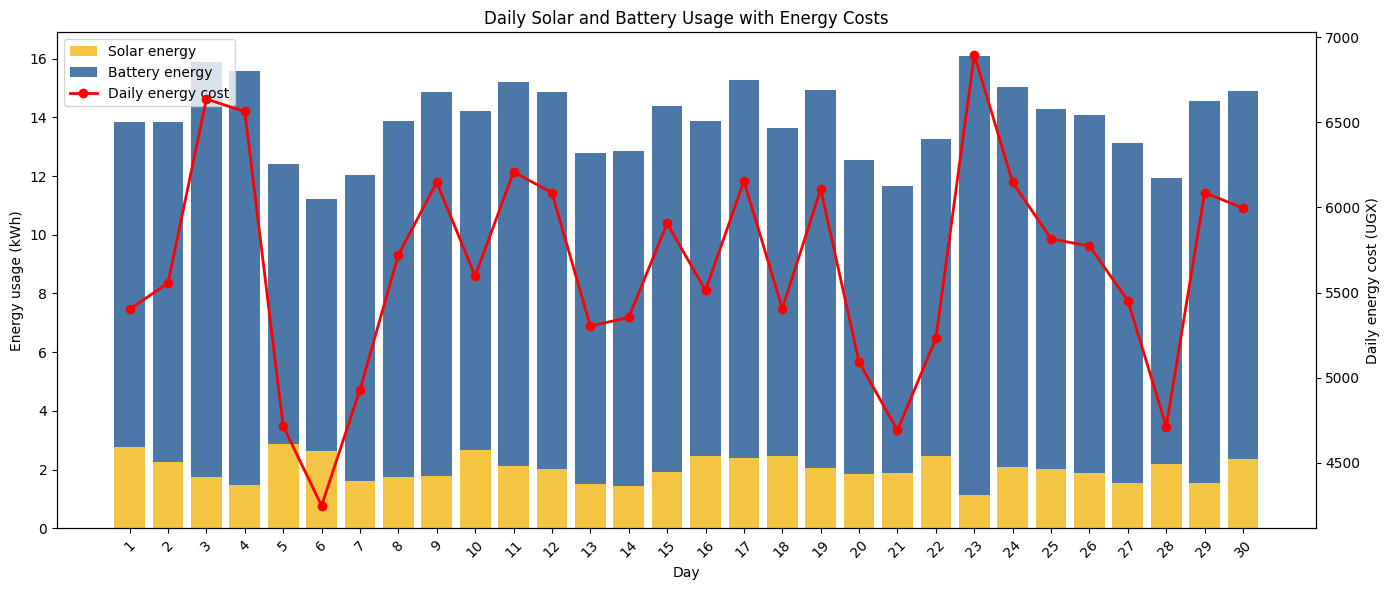

In [17]:
fig, ax1 = plt.subplots(figsize=(14, 6))

# Stacked bars for daily energy usage
ax1.bar(
    final_results["day"],
    final_results["solar_kwh"],
    label="Solar energy",
    color="#F4C542"
)

ax1.bar(
    final_results["day"],
    final_results["battery_kwh"],
    bottom=final_results["solar_kwh"],
    label="Battery energy",
    color="#4C78A8"
)

ax1.set_xlabel("Day")
ax1.set_ylabel("Energy usage (kWh)")
ax1.set_title("Daily Solar and Battery Usage with Energy Costs")
ax1.set_xticks(final_results["day"])
ax1.tick_params(axis="x", rotation=45)

# Secondary axis for daily cost
ax2 = ax1.twinx()

ax2.plot(
    final_results["day"],
    final_results["total_cost_ugx"],
    color="red",
    marker="o",
    linewidth=2,
    label="Daily energy cost"
)

ax2.set_ylabel("Daily energy cost (UGX)")

# Combine legends from both axes
bars_labels = ax1.get_legend_handles_labels()
line_labels = ax2.get_legend_handles_labels()

ax1.legend(
    bars_labels[0] + line_labels[0],
    bars_labels[1] + line_labels[1],
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [18]:
hybrid_grid = HybridMicroGrid()

print("Hybrid determinant:", hybrid_grid.hybrid_determinant)
print("Hybrid condition number:", hybrid_grid.hybrid_condition_number)

hybrid_result = hybrid_grid.solve_day(
    d1=30,
    d2=20,
    d3=25
)

print("\nHybrid dispatch result:")
print(hybrid_result)

Hybrid determinant: -4.999999999999999
Hybrid condition number: 7.715758300081699

Hybrid dispatch result:
{'solar_kwh': np.float64(2.0), 'battery_kwh': np.float64(12.0), 'diesel_kwh': np.float64(10.999999999999998), 'feasible': True}


In [19]:
# Use average demand from the 30-day dataset
base_d1 = float(demand_df["D1_kwh"].mean())
base_d2 = float(demand_df["D2_kwh"].mean())

# Reproducible random generator
rng = np.random.default_rng(42)

# Generate 1,000 independent demand perturbations between -5% and +5%
n_simulations = 1000

d1_simulated = base_d1 * (
    1 + rng.uniform(-0.05, 0.05, n_simulations)
)

d2_simulated = base_d2 * (
    1 + rng.uniform(-0.05, 0.05, n_simulations)
)

# Solve all simulated demand systems simultaneously
simulated_demands = np.vstack([d1_simulated, d2_simulated])
simulated_solutions = solve(grid.matrix, simulated_demands)

sensitivity_df = pd.DataFrame({
    "D1_simulated": d1_simulated,
    "D2_simulated": d2_simulated,
    "solar_kwh": simulated_solutions[0, :],
    "battery_kwh": simulated_solutions[1, :]
})

# Summarise the simulation
display(
    sensitivity_df[
        ["solar_kwh", "battery_kwh"]
    ].describe(percentiles=[0.025, 0.5, 0.975]).round(3)
)

# Check whether any simulated solutions are infeasible
infeasible_count = (
    (sensitivity_df["solar_kwh"] < 0) |
    (sensitivity_df["battery_kwh"] < 0)
).sum()

print("Number of simulations:", n_simulations)
print("Infeasible simulated solutions:", infeasible_count)

,solar_kwh,battery_kwh
count,1000.000,1000.000
mean,2.036,11.860
std,0.289,0.777
min,1.370,10.136
2.5%,1.502,10.475
50%,2.025,11.875
97.5%,2.583,13.253
max,2.695,13.589


Number of simulations: 1000
Infeasible simulated solutions: 0


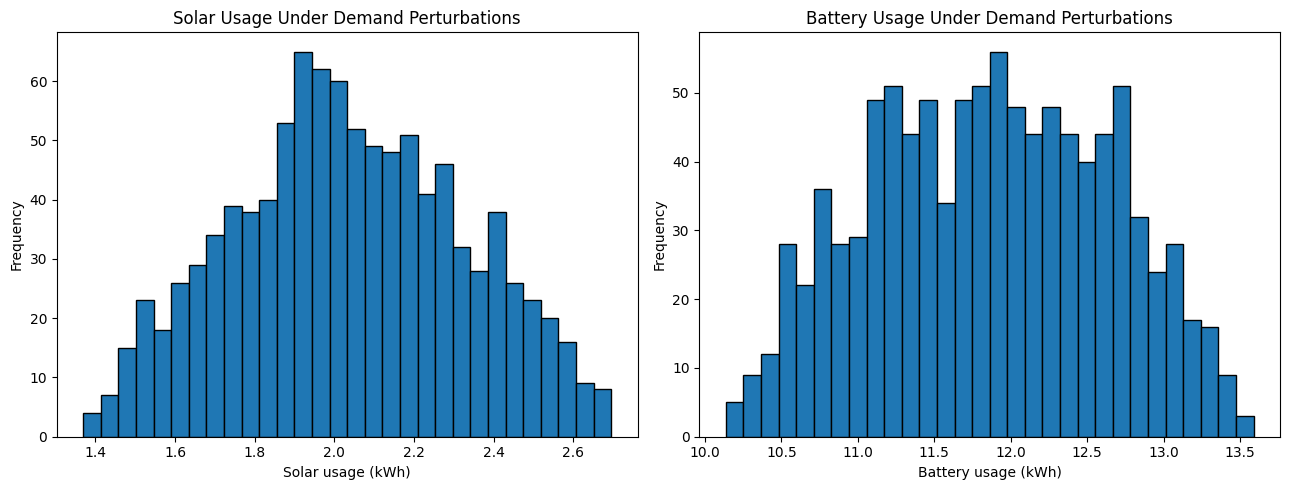

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Solar energy distribution
axes[0].hist(
    sensitivity_df["solar_kwh"],
    bins=30,
    edgecolor="black"
)
axes[0].set_title("Solar Usage Under Demand Perturbations")
axes[0].set_xlabel("Solar usage (kWh)")
axes[0].set_ylabel("Frequency")

# Battery energy distribution
axes[1].hist(
    sensitivity_df["battery_kwh"],
    bins=30,
    edgecolor="black"
)
axes[1].set_title("Battery Usage Under Demand Perturbations")
axes[1].set_xlabel("Battery usage (kWh)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [21]:
base_solution = grid.solve_day(base_d1, base_d2)

for source in ["solar_kwh", "battery_kwh"]:
    simulated_mean = sensitivity_df[source].mean()
    simulated_sd = sensitivity_df[source].std()
    baseline = base_solution[source]

    print(f"\n{source}")
    print(f"Baseline usage: {baseline:.3f} kWh")
    print(f"Simulated mean: {simulated_mean:.3f} kWh")
    print(f"Simulated standard deviation: {simulated_sd:.3f} kWh")


solar_kwh
Baseline usage: 2.028 kWh
Simulated mean: 2.036 kWh
Simulated standard deviation: 0.289 kWh

battery_kwh
Baseline usage: 11.877 kWh
Simulated mean: 11.860 kWh
Simulated standard deviation: 0.777 kWh


# Findings and Limitations

The solar micro-grid dispatch model was developed using a system of two linear equations to estimate daily solar and battery energy requirements. A seeded random generator was used to create a synthetic dataset of 30 days with a weekly demand pattern and random noise. All 30 days produced non-negative solutions, indicating that the generated demands were feasible under the specified model.

The loop-based and vectorised approaches returned identical results. In the timing test, the vectorised approach took approximately 0.139 seconds for 100 runs, compared with 0.452 seconds for the loop-based approach. This was about 3.26 times faster in this experiment. Descriptive statistics showed that battery usage varied more from day to day than solar usage. Using the illustrative rates of UGX 150 per solar kWh and UGX 450 per battery kWh, the model also estimated daily and total 30-day energy costs.

The non-negative least-squares method provided a fallback for infeasible exact solutions. The hybrid micro-grid extension successfully introduced diesel as a third energy source. In 1,000 Monte Carlo simulations with independent demand perturbations of ±5%, all solutions remained feasible. Battery usage had a simulated standard deviation of 0.777 kWh, compared with 0.289 kWh for solar.

The main limitation is that the demands and cost rates were illustrative rather than measured. The model also excludes battery capacity, charging efficiency, storage losses, equipment constraints, and changing solar availability. Therefore, its results demonstrate mathematical dispatch planning rather than a validated operational plan for a real health centre.